# 7. Aperture versus focal length (descriptive)

**Purpose:** see how the f-number used depends on focal length. Each burst counts once.

The lens is a Sony E 18–135 mm F3.5–5.6 OSS zoom. Its name gives the widest opening at the two ends: f/3.5 at 18 mm and f/5.6 at 135 mm. The name does not give the opening at each focal length, so those two values are drawn as references only. The exact limit is stored per photo in the `MaxApertureValue` tag, which this project does not read yet.

**Burst rule:** consecutive files in the same folder with an identical `DateTimeOriginal` (the same second) form one burst. The first frame represents it, including its aperture.

**Data:** served from the `.cache/` folder when it is less than one day old.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent  # run from the notebooks/ folder
if not (ROOT / "focal_data.py").is_file():
    raise FileNotFoundError(f"focal_data.py not found in {ROOT}; run from notebooks/")
sys.path.insert(0, str(ROOT))

from focal_data import focal_band, group_bursts, load_records

DIRECTORY, DEPTH = r"D:\DCIM", 1
records = load_records(DIRECTORY, DEPTH)
bursts = group_bursts(records)

## Scatter of focal length and f-number
Focal lengths are jittered by ±0.4 mm so overlapping points stay visible. Lower f-number = wider.

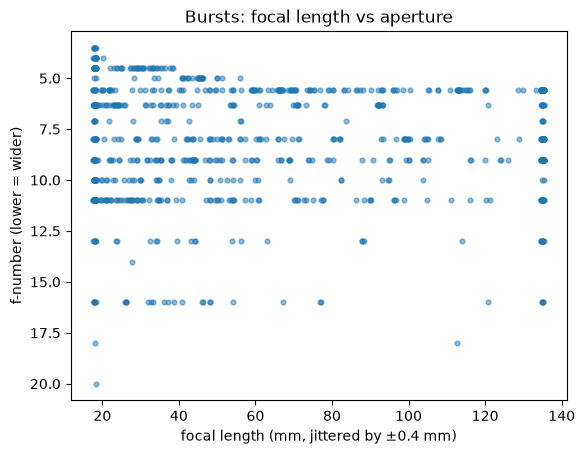

In [2]:
rng = np.random.default_rng(0)
jitter = rng.uniform(-0.4, 0.4, len(bursts))
plt.scatter(bursts["focal_mm"] + jitter, bursts["aperture"], s=12, alpha=0.5)
plt.gca().invert_yaxis()
plt.xlabel("focal length (mm, jittered by ±0.4 mm)")
plt.ylabel("f-number (lower = wider)")
plt.title("Bursts: focal length vs aperture")
plt.show()

## Heatmap: focal band by f-stop
Bursts in each focal length band (the bands from notebook 05) and f-stop.

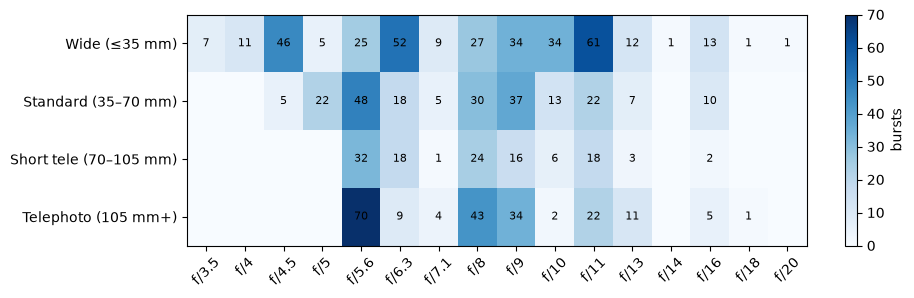

,f/3.5,f/4,f/4.5,f/5,f/5.6,f/6.3,f/7.1,f/8,f/9,f/10,f/11,f/13,f/14,f/16,f/18,f/20
focal_mm,,,,,,,,,,,,,,,,
Wide (≤35 mm),7,11,46,5,25,52,9,27,34,34,61,12,1,13,1,1
Standard (35–70 mm),0,0,5,22,48,18,5,30,37,13,22,7,0,10,0,0
Short tele (70–105 mm),0,0,0,0,32,18,1,24,16,6,18,3,0,2,0,0
Telephoto (105 mm+),0,0,0,0,70,9,4,43,34,2,22,11,0,5,1,0


In [3]:
heat = pd.crosstab(focal_band(bursts["focal_mm"]), bursts["aperture"])
heat.columns = [f"f/{v:g}" for v in heat.columns]
values = heat.to_numpy()

fig, ax = plt.subplots(figsize=(10, 3))
image = ax.imshow(values, cmap="Blues", aspect="auto")
ax.set_xticks(range(values.shape[1]), list(heat.columns), rotation=45)
ax.set_yticks(range(values.shape[0]), [str(band) for band in heat.index])
for (i, j), count in np.ndenumerate(values):
    if count:
        ax.text(j, i, count, ha="center", va="center", fontsize=8)
fig.colorbar(image, ax=ax, label="bursts")
plt.show()
heat

## Median aperture per focal band
The typical f-number in each band, and the share of bursts at f/4.5 or wider.

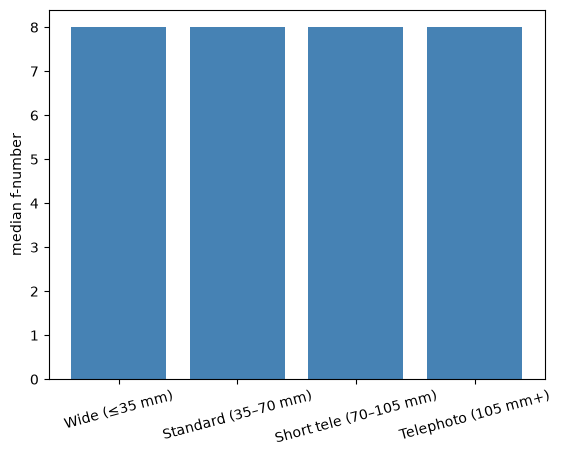

,bursts,median f-number,f/4.5 or wider %
band,,,
Wide (≤35 mm),339,8.0,18.9
Standard (35–70 mm),217,8.0,2.3
Short tele (70–105 mm),120,8.0,0.0
Telephoto (105 mm+),201,8.0,0.0


In [4]:
per_band = (
    bursts.assign(band=focal_band(bursts["focal_mm"]))
    .groupby("band", observed=True)["aperture"]
    .agg(bursts="count", median_f="median", wide_share=lambda s: (s <= 4.5).mean() * 100)
    .round(1)
    .rename(columns={"median_f": "median f-number", "wide_share": "f/4.5 or wider %"})
)
plt.bar(per_band.index.astype(str), per_band["median f-number"], color="steelblue")
plt.ylabel("median f-number")
plt.xticks(rotation=15)
plt.show()
per_band

## Narrowest and widest f-number at each focal length
For each focal length (rounded to 1 mm): the lowest and highest f-number used. The dotted and dashed lines are the lens name's two ends, f/3.5 and f/5.6. They are references, not measured limits.

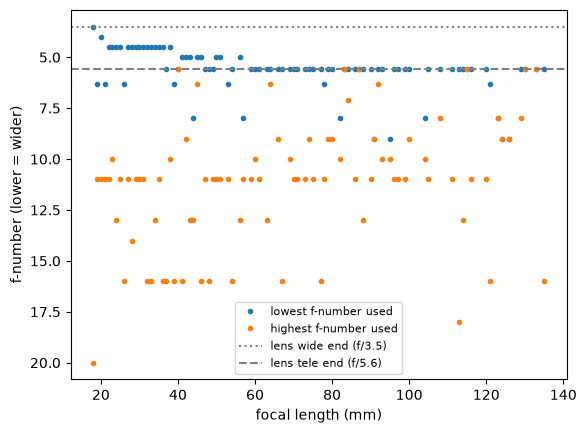

In [5]:
per_mm = bursts.groupby(bursts["focal_mm"].round(0))["aperture"].agg(["min", "max"])
plt.plot(per_mm.index, per_mm["min"], "o", ms=3, label="lowest f-number used")
plt.plot(per_mm.index, per_mm["max"], "o", ms=3, label="highest f-number used")
plt.axhline(3.5, ls=":", color="gray", label="lens wide end (f/3.5)")
plt.axhline(5.6, ls="--", color="gray", label="lens tele end (f/5.6)")
plt.gca().invert_yaxis()
plt.xlabel("focal length (mm)")
plt.ylabel("f-number (lower = wider)")
plt.legend(fontsize=8)
plt.show()

## Takeaways
Figures from this run (885 images, 877 bursts). They describe this folder only.

1. **Wide openings appear only at short focal lengths.** Of the bursts in the wide band (35 mm and shorter), 18.9% are f/4.5 or wider. In the standard band it is 2.3%. From 70 mm up, no burst is wider than f/5.6, which matches the lens's long end.
2. **The median f-number is f/8 in every band.** Focal length does not change the typical stop in this folder.
3. **f/3.5 and f/4 were used only at short focal lengths.** Both appear only in the wide band, which matches the lens's wide end. The lowest f-number in each focal band is shown in the per-millimetre plot.
4. **Exact limits need more data.** The per-photo MaxApertureValue tag would give the widest opening at each focal length. This project does not read it yet.